# COMPAR concordance of reportable output

How much of the **reported** oncoanalyser output changes between two runs of the same samples,
measured with [COMPAR](https://github.com/hartwigmedical/hmftools/tree/master/compar). Two
comparisons are drawn side by side:

| Comparison | Samples | Reference ("old") | Test ("new") |
| --- | --- | --- | --- |
| Fresh-frozen tumour/normal vs tumour-only | COLO829, HCC1187, HCC1395, HCC1954, HG008 | FF tumour/normal (TN) | FF tumour-only (TO) |
| NovaSeq 6000 vs NovaSeq X | HG008 (tumour/normal), downsampled to the same coverage | NovaSeq 6000 (PCR-free) | NovaSeq X (PCR) |

| Panel | Content | Source |
| --- | --- | --- |
| A · concordance per category | shared / different / reference-only / test-only records, both comparisons | every `<prefix>.<category>.tsv` |
| B · purity and QC change table | PURPLE purity, ploidy, burden and status metrics, *reference → test* | `<prefix>.purity.tsv` |
| C · reporting thresholds | TMB, TML and MS indels/Mb against the PURPLE thresholds | `<prefix>.purity.tsv` |
| D · root causes | why each FF TN-only / TO-only / different call differs | manual annotation, in this notebook (section 4.1) |

Throughout, **blue = reference run** (TN, NovaSeq 6000), **orange = test run** (TO, NovaSeq X),
red = same record with a different call/status, grey = shared.

Point the Configuration cell at your COMPAR output folders and run all cells; see **Data access**
below for what the inputs are and how to produce them.

## Data access

Unlike the other notebooks, this one does **not** read from the public buckets: COMPAR output is
not published. COMPAR compares two oncoanalyser runs, so you produce its output yourself from two
sets of run folders — for example the public ones in `gs://hartwig-oapaper-celllines` — and point
this notebook at the result.

### What this notebook reads (< 1 MB)

One COMPAR **reportable** output folder per comparison — the folder passed as `-output_dir` to a
COMPAR run at the default match level (`REPORTABLE`). It holds one TSV per category:

```text
<COMPAR_OUTPUT[comparison]>/
  <prefix>.purity.tsv               panels A, B, C
  <prefix>.driver.tsv               panels A, D
  <prefix>.somatic_variant.tsv      panels A, D
  <prefix>.disruption.tsv           panels A, D
  <prefix>.lilac.tsv                panels A, D
  <prefix>.<other category>.tsv     panel A
```

`<prefix>` is `<output_id>.compar` for a cohort run (`-sample_id_file`, with a `SampleId`
column in every file) or `<sample>.<output_id>` for a single-sample run (the sample ID is then
taken from the file name). The cohort-wide `<prefix>.tsv` summary is ignored; it duplicates the
per-category files. Categories that were not compared simply have no file, and panel A says so.

The manual root-cause annotation behind panel D is written into this notebook
(`MANUAL_ANNOTATIONS`, section 4.1); nothing else needs downloading. It is keyed on sample ID and
COMPAR record key, so it only labels records of the FF TN vs TO comparison of these five cell lines;
anything it does not cover is drawn as *Not annotated*.

> **Panel D is manual curation, not COMPAR output.** Its root causes come from a person reviewing
> the discordant records of *this* dataset. If you run COMPAR on your own data, you have to redo
> that curation and adapt the code to get a similar figure — see the note at panel D.

### Producing the COMPAR output

The figure was made with COMPAR v1.6.0. Per comparison:

```bash
java -jar compar.jar \
    -categories "<comma-separated categories>" \
    -sample_id_file sample_ids.csv \
    -driver_gene_panel DriverGenePanel.38.tsv \
    -sample_dir_old "<reference runs>/*" \
    -sample_dir_new "<test runs>/*" \
    -somatic_unfiltered_vcf_old "<reference runs>/*/sage/somatic/*.sage.somatic.vcf.gz" \
    -somatic_unfiltered_vcf_new "<test runs>/*/sage/somatic/*.sage.somatic.vcf.gz" \
    -output_id compar \
    -include_matches \
    -thresholds "TotalFragments:1000000:-1;FittedFragments:1000000:-1;DiscardedAlignmentFragments:1000000:-1;TumorCopyNumber:1000000:-1" \
    -output_dir output_reportable
```

* `-include_matches` is required: panel A needs the shared records, not only the differences.
* `*` in `-sample_dir_*` is replaced by the sample ID, so the run folders (or symlinks to them)
  must be named after the tumour sample, e.g. `HCC1187T/`.
* Categories: `PURITY,DRIVER,SOMATIC_VARIANT,DISRUPTION,FUSION,LILAC,VIRUS,TUMOR_FLAGSTAT,TUMOR_BAM_METRICS,CDR3_SEQUENCE,CDR3_LOCUS_SUMMARY,TELOMERE_LENGTH,COPY_NUMBER,GENE_COPY_NUMBER`
  for tumour/normal vs tumour-only (a tumour-only run has no germline output); all categories,
  including the germline and `CUPPA`, `CHORD`, `PEACH`, `SIGS` ones, for NovaSeq 6000 vs X.

### Where the input can live

* **A local folder** — set the entry in `COMPAR_OUTPUT` to its absolute path.
* **A `gs://` folder** — the TSVs are copied once into `data/ext_compar_concordance/` with
  `gsutil` and re-used afterwards. Needs the Google Cloud SDK and `gcloud auth login`.

## 1 · Configuration

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd

FFTN_VS_FFTO = "fftn_vs_ffto"
NOVA_COMP = "nova6000_vs_novax"

# ============================================================================
# CONFIGURATION — point these at the REPORTABLE output folder of your own COMPAR runs.
#
# COMPAR output is not in the public buckets: run COMPAR yourself (see Data access) and set each
# entry to the folder you passed as -output_dir, i.e. the one holding <prefix>.<category>.tsv.
# A local absolute path and a gs:// folder both work.
# ============================================================================
COMPAR_OUTPUT = {
    FFTN_VS_FFTO: None,   # e.g. "/data/compar/fftn_vs_ffto/output_reportable"
    NOVA_COMP:    None,   # e.g. "gs://my-bucket/compar/nova6000_vs_novax/output_reportable"
}
# ============================================================================

# gs:// inputs are cached under data/ext_compar_concordance/<folder>/, keyed on the source folder.
CACHE_ROOT = Path("data") / "ext_compar_concordance"
EXPORT_DIR = Path("figures"); EXPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_STEM = "ext_compar_concordance"

COMPARISONS = {
    FFTN_VS_FFTO: {
        "directory": COMPAR_OUTPUT[FFTN_VS_FFTO],
        "title": "Fresh-frozen: tumor-normal vs tumor-only",
        "old": "Tumor-normal (TN)",
        "new": "Tumor-only (TO)",
        "old_short": "TN",
        "new_short": "TO",
        "missing_reason": "not run in tumor-only mode",
    },
    NOVA_COMP: {
        "directory": COMPAR_OUTPUT[NOVA_COMP],
        "title": "NovaSeq 6000 vs NovaSeq X (tumor-normal)",
        "old": "NovaSeq 6000",
        "new": "NovaSeq X",
        "old_short": "6000",
        "new_short": "X",
        "missing_reason": "not run",
    },
}

# A VALUE mismatch in these categories means the same call was made with slightly different
# annotations (e.g. driver likelihood, biallelic probability), so it counts as a match.
CATEGORIES_WHERE_VALUE_IS_MATCH = {
    "DRIVER", "SOMATIC_VARIANT", "GERMLINE_VARIANT", "GERMLINE_AMP_DEL", "DISRUPTION",
    "FUSION", "GERMLINE_SV", "VIRUS", "CDR3_SEQUENCE", "COPY_NUMBER",
}
# LILAC rows that only differ in these fields have the same HLA typing, so they count as a match.
LILAC_NON_CALL_FIELDS = {"HlaYAllele", "TotalFragments", "FittedFragments", "DiscardedAlignmentFragments"}
# CUPPA_IMAGE is a pixel diff of the CUPPA plot; the CUPPA calls themselves are compared in CUPPA.
EXCLUDED_CATEGORIES = {"CUPPA_IMAGE"}

# A VALUE mismatch only counts as major when one of these fields differs, i.e. a reported call or status
# changes (TMB 14 -> 20 is still TMB HIGH). Value differences in all other categories/fields (e.g. duplicate
# rate, telomere length) are minor.
MAJOR_VALUE_FIELDS = {
    "PURITY": {"QcStatus", "TmbStatus", "TmlStatus", "MsStatus", "Gender", "FitMethod", "GermlineAberrations"},
    "LILAC": {"Alleles", "Status", "SomaticVariants"},
    "CHORD": {"Status", "Type"},
    "CUPPA": {"top_cancer_type"},
}

MISMATCH_ORDER = ["MATCH", "VALUE_MINOR", "VALUE_MAJOR", "OLD_ONLY", "NEW_ONLY"]

# Reporting thresholds PURPLE uses for the status fields (TmbStatus, TmlStatus, MsStatus).
THRESHOLDS = {"TmbPerMb": 10, "Tml": 140, "MsIndelsPerMb": 4}

for _c, _info in COMPARISONS.items():
    print(f"{_c:18s} {_info['directory']}")

## 2 · Loading COMPAR output

Both folders are read the same way: one file per category (`<prefix>.<category>.tsv`), so the
wide per-category tables are available for the purity panel. Sample IDs come from the `SampleId`
column (cohort run) or the file prefix (single-sample run). `INVALID_*` rows (category not
produced by either run) are dropped. A `gs://` folder is staged into the local cache first.

In [2]:
import hashlib
import subprocess


def cache_dir(folder):
    """Local cache path for a gs:// folder, readable and keyed on the full source path."""
    src = str(folder).rstrip("/")
    tail = [p for p in src.split("//")[-1].split("/") if p][-3:]
    label = re.sub(r"[^A-Za-z0-9]+", "-", "-".join(tail)).strip("-")
    return CACHE_ROOT / f"{label}-{hashlib.sha1(src.encode()).hexdigest()[:6]}"


def locate_compar_folder(comparison, folder):
    """The local folder holding the COMPAR TSVs of one comparison; copies a gs:// folder down once."""
    if folder is None:
        raise ValueError(f"COMPAR_OUTPUT[{comparison!r}] is not set: point it at the reportable output "
                         "folder of your COMPAR run (see Data access).")
    folder = str(folder).rstrip("/")
    if folder.startswith("gs://"):
        local = cache_dir(folder)
        if not any(local.glob("*.tsv")):
            local.mkdir(parents=True, exist_ok=True)
            r = subprocess.run(["gsutil", "-m", "cp", f"{folder}/*.tsv", str(local)],
                               capture_output=True, text=True)
            if r.returncode != 0:
                raise RuntimeError(f"gsutil cp {folder}/*.tsv failed:\n{r.stderr.strip()}")
    else:
        local = Path(folder).expanduser()
        if not local.is_dir():
            raise FileNotFoundError(f"COMPAR_OUTPUT[{comparison!r}] = {folder} is not a folder")
    if not any(local.glob("*.tsv")):
        raise FileNotFoundError(f"no COMPAR *.tsv files in {folder}")
    return local


CATEGORY_FILE_PATTERN = re.compile(r"\.([a-z0-9_]+)\.tsv$")


def load_compar_directory(directory):
    """Returns (long table of all records, {category: wide per-category table})."""
    records, per_category = [], {}
    for path in sorted(directory.glob("*.tsv")):
        category = CATEGORY_FILE_PATTERN.search(path.name).group(1).upper()
        if category == "COMPAR":  # the cohort-wide summary file duplicates the per-category files
            continue
        table = pd.read_csv(path, sep="\t", keep_default_na=False, na_values=[""])
        if "SampleId" not in table.columns:
            table.insert(0, "SampleId", path.name.split(".")[0])
        table = table[~table["MismatchType"].str.startswith("INVALID")]
        per_category[category] = table
        long = table[["SampleId", "MismatchType", "Key", "Differences"]].copy()
        long.insert(1, "Category", category)
        records.append(long)
    return pd.concat(records, ignore_index=True), per_category


RECORDS, PER_CATEGORY = {}, {}
for comparison, info in COMPARISONS.items():
    RECORDS[comparison], PER_CATEGORY[comparison] = load_compar_directory(
        locate_compar_folder(comparison, info["directory"]))
    print(f"{comparison}: {len(RECORDS[comparison])} records, "
          f"samples={sorted(RECORDS[comparison]['SampleId'].unique())}")

fftn_vs_ffto: 394 records, samples=['COLO829v012T', 'HCC1187T', 'HCC1395T', 'HCC1954T', 'HG008T']


nova6000_vs_novax: 74 records, samples=['HG008T']


## 3 · Plotting style

In [3]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7, "axes.titleweight": "bold",
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2.5, "ytick.major.size": 0, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"

# Same meaning in every panel: blue = reference run, orange = test run.
MISMATCH_COLORS = {
    "MATCH": "#dddcd6",        # shared: neutral, so the differences stand out
    "VALUE_MINOR": "#a9a69c",  # same record, value differs but no call/status changes
    "VALUE_MAJOR": "#e34948",  # same record, a call/status changes
    "OLD_ONLY": "#2a78d6",     # reference run only
    "NEW_ONLY": "#eb6834",     # test run only
}
OLD_COLOR = MISMATCH_COLORS["OLD_ONLY"]
NEW_COLOR = MISMATCH_COLORS["NEW_ONLY"]

# Tint of VALUE_MAJOR, used in panel B for status flips and the threshold crossings that cause them.
STATUS_FLIP_COLOR = "#f9d2cf"


def mismatch_labels(comparison):
    info = COMPARISONS[comparison]
    return {
        "MATCH": "Shared",
        "VALUE_MINOR": "Different value (minor)",
        "VALUE_MAJOR": "Different call/status",
        "OLD_ONLY": f"{info['old']} only",
        "NEW_ONLY": f"{info['new']} only",
    }


def text_color_on(fill):
    r, g, b = to_rgb(fill)
    return INK if (0.299 * r + 0.587 * g + 0.114 * b) > 0.55 else "white"

## 4 · Classifying each record

In [4]:
def difference_fields(differences):
    if pd.isna(differences):
        return set()
    return {entry.split("(")[0].strip() for entry in str(differences).split(";") if entry.strip()}


def classify(records):
    """Adds `Status` (MATCH / VALUE_MINOR / VALUE_MAJOR / OLD_ONLY / NEW_ONLY) using the configured rules."""
    records = records[~records["Category"].isin(EXCLUDED_CATEGORIES)].copy()
    status = records["MismatchType"].replace({"FULL_MATCH": "MATCH"})
    is_value = status == "VALUE"
    status = status.mask(is_value & records["Category"].isin(CATEGORIES_WHERE_VALUE_IS_MATCH), "MATCH")
    lilac_same_typing = records["Differences"].map(lambda d: difference_fields(d) <= LILAC_NON_CALL_FIELDS)
    status = status.mask(is_value & (records["Category"] == "LILAC") & lilac_same_typing, "MATCH")
    is_major = pd.Series([bool(difference_fields(d) & MAJOR_VALUE_FIELDS.get(c, set()))
                          for c, d in zip(records["Category"], records["Differences"])], index=records.index)
    status = status.mask((status == "VALUE") & is_major, "VALUE_MAJOR").replace({"VALUE": "VALUE_MINOR"})
    records["Status"] = status
    return records


def concordance_counts(records):
    counts = pd.crosstab(records["Category"], records["Status"])
    return counts.reindex(columns=MISMATCH_ORDER, fill_value=0)


CLASSIFIED = {comparison: classify(records) for comparison, records in RECORDS.items()}
COUNTS = {comparison: concordance_counts(records) for comparison, records in CLASSIFIED.items()}
pd.concat(COUNTS, axis=1).fillna(0).astype(int)

fftn_vs_ffto                                            \
Status                      MATCH VALUE_MINOR VALUE_MAJOR OLD_ONLY NEW_ONLY   
Category                                                                      
CDR3_LOCUS_SUMMARY             30           0           0        0        0   
CDR3_SEQUENCE                  68           0           0        0        0   
DISRUPTION                     28           0           0        0        9   
DRIVER                        100           0           0       41       21   
FUSION                          1           0           0        0        0   
LILAC                          17           0           8        0        0   
PURITY                          0           2           3        0        0   
SOMATIC_VARIANT                40           0           0        0       11   
TELOMERE_LENGTH                 5           0           0        0        0   
TUMOR_BAM_METRICS               5           0           0        0        0   
TUMOR_FLAGSTAT                  5           0           0        0        0   
CHORD                           0           0           0        0        0   
CUPPA                           0           0           0        0        0   
GERMLINE_BAM_METRICS            0           0           0        0        0   
GERMLINE_FLAGSTAT               0           0           0        0        0   
PEACH                           0           0           0        0        0   

                     nova6000_vs_novax                                   \
Status                           MATCH VALUE_MINOR VALUE_MAJOR OLD_ONLY   
Category                                                                  
CDR3_LOCUS_SUMMARY                   6           0           0        0   
CDR3_SEQUENCE                        0           0           0        0   
DISRUPTION                           2           0           0        0   
DRIVER                              14           0           0        0   
FUSION                               0           0           0        0   
LILAC                                5           0           0        0   
PURITY                               1           0           0        0   
SOMATIC_VARIANT                      5           0           0        0   
TELOMERE_LENGTH                      0           1           0        0   
TUMOR_BAM_METRICS                    0           1           0        0   
TUMOR_FLAGSTAT                       1           0           0        0   
CHORD                                1           0           0        0   
CUPPA                                4           0           0        0   
GERMLINE_BAM_METRICS                 0           1           0        0   
GERMLINE_FLAGSTAT                    1           0           0        0   
PEACH                                3           0           0        0   

                               
Status               NEW_ONLY  
Category                       
CDR3_LOCUS_SUMMARY          0  
CDR3_SEQUENCE              27  
DISRUPTION                  0  
DRIVER                      0  
FUSION                      0  
LILAC                       0  
PURITY                      0  
SOMATIC_VARIANT             0  
TELOMERE_LENGTH             0  
TUMOR_BAM_METRICS           0  
TUMOR_FLAGSTAT              0  
CHORD                       0  
CUPPA                       0  
GERMLINE_BAM_METRICS        0  
GERMLINE_FLAGSTAT           0  
PEACH                       0

### 4.1 · Manual annotations (FF TN vs TO)

`MANUAL_ANNOTATIONS` below holds the hand-written `Conclusion` for each record of the FF TN vs TO
comparison that was reviewed. It explains each TN-only / TO-only / different
record. Driver rows that say *"See somatic variant tab"* / *"See disruptions tab"* are resolved to
the conclusion of the matching somatic variant (same sample, same gene) or disruption. Each
conclusion is then mapped to one of the root causes below.

These entries are **manual curation of this paper's dataset**; read the note at panel D
before using it with your own COMPAR output.

In [5]:
# Manual root-cause annotation of the FF tumour/normal vs tumour-only differences (panel D).
# Hand-curated for THIS dataset: one entry per discordant COMPAR record, keyed on (category, sample, key).
# On your own COMPAR output, replace these entries with your own curation (see the note at panel D).
# NewGene is only needed for somatic variants, to resolve "See somatic variant tab" driver notes.
MANUAL_ANNOTATIONS = [
    # (Category, SampleId, Key, NewGene, Conclusion)
    # DRIVER
    ("DRIVER", "HCC1187T", "AMP_CCND3", "", "Was candidate amplification, but no longer due to ploidy change"),
    ("DRIVER", "HCC1395T", "AMP_CRLF2", "", "Was candidate amplification, but no longer due to ploidy change"),
    ("DRIVER", "HG008T", "AMP_DLL3", "", "Was candidate amplification, but no longer due to ploidy change"),
    ("DRIVER", "HCC1187T", "AMP_H3C13", "", "Was candidate amplification, but no longer due to ploidy change"),
    ("DRIVER", "HCC1187T", "AMP_MCL1", "", "Was candidate amplification, but no longer due to ploidy change"),
    ("DRIVER", "HCC1187T", "AMP_SETDB1", "", "Was candidate amplification, but no longer due to ploidy change"),
    ("DRIVER", "HCC1187T", "DEL_AJUBA", "", "Probably messed up in TN due to non-diploid germline chr14"),
    ("DRIVER", "HCC1187T", "DEL_DICER1", "", "Probably messed up in TN due to non-diploid germline chr14"),
    ("DRIVER", "HCC1187T", "DEL_FANCM", "", "Probably messed up in TN due to non-diploid germline chr14"),
    ("DRIVER", "HCC1187T", "DEL_LINC01001", "", "Probably messed up in TN due to non-diploid germline chr11"),
    ("DRIVER", "HCC1187T", "DEL_PRKD1", "", "Probably messed up in TN due to non-diploid germline chr14"),
    ("DRIVER", "HCC1187T", "DEL_SAV1", "", "Probably messed up in TN due to non-diploid germline chr14"),
    ("DRIVER", "HCC1187T", "DEL_SIX1", "", "Probably messed up in TN due to non-diploid germline chr14"),
    ("DRIVER", "HG008T", "DEL_SUZ12", "", "Marginal difference around threshold"),
    ("DRIVER", "HCC1187T", "DEL_ZFP36L1", "", "Probably messed up in TN due to non-diploid germline chr14"),
    ("DRIVER", "HCC1954T", "DISRUPTION_AXIN1", "", "See disruptions tab"),
    ("DRIVER", "HCC1187T", "DISRUPTION_ERBB4", "", "See disruptions tab"),
    ("DRIVER", "HCC1187T", "DISRUPTION_LATS2", "", "See disruptions tab"),
    ("DRIVER", "HG008T", "DISRUPTION_MSH3", "", "See disruptions tab"),
    ("DRIVER", "HG008T", "DISRUPTION_NCOR1", "", "See disruptions tab"),
    ("DRIVER", "HCC1187T", "DISRUPTION_NOTCH1", "", "See disruptions tab"),
    ("DRIVER", "HCC1954T", "DISRUPTION_PTCH1", "", "See disruptions tab"),
    ("DRIVER", "HCC1395T", "DISRUPTION_SMARCC1", "", "See disruptions tab"),
    ("DRIVER", "HG008T", "DISRUPTION_SMARCC1", "", "See disruptions tab"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_AIP", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_ATM", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1395T", "GERMLINE_DELETION_BRCA1", "", "Germline driver (HET deletion)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_BRCA2", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_CHEK1", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_DICER1", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_MEN1", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_RAD51B", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_RB1", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_SDHAF2", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_SDHD", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DELETION_WT1", "", "Germline driver (actually AMP, not high enough for somatic AMP)"),
    ("DRIVER", "HCC1187T", "GERMLINE_DISRUPTION_MLH1", "", "Germline driver. (1 read support in tumor)."),
    ("DRIVER", "HCC1395T", "GERMLINE_MUTATION_BRCA1", "", "Germline driver. Matches new BRCA1 somatic mutation"),
    ("DRIVER", "HCC1395T", "GERMLINE_MUTATION_CHEK2", "", "Germline driver (Not present in tumor)"),
    ("DRIVER", "HCC1954T", "LOH_BRCA1", "", "chr17. Probably the missing BAF points."),
    ("DRIVER", "HCC1187T", "LOH_BRCA1", "", "chr17. Probably the missing BAF points."),
    ("DRIVER", "HCC1187T", "LOH_BRCA2", "", "chr13. Probably the missing BAF points."),
    ("DRIVER", "HCC1187T", "LOH_EPCAM", "", "chr2. Probably the missing BAF points."),
    ("DRIVER", "HG008T", "LOH_MLH1", "", "chr3. Probably the missing BAF points."),
    ("DRIVER", "HCC1187T", "LOH_MLH1", "", "chr3. Probably the missing BAF points."),
    ("DRIVER", "HCC1187T", "LOH_MSH2", "", "chr2. Probably the missing BAF points."),
    ("DRIVER", "HCC1187T", "LOH_MSH6", "", "chr2. Probably the missing BAF points."),
    ("DRIVER", "HG008T", "LOH_PALB2", "", "chr16. Probably the missing BAF points."),
    ("DRIVER", "HCC1187T", "LOH_RAD51B", "", "chr14. Non-diploid germline messes up CN calling in TN."),
    ("DRIVER", "HCC1395T", "LOH_RAD51C", "", "chr17. Probably the missing BAF points."),
    ("DRIVER", "HCC1187T", "LOH_RAD51C", "", "chr17. Probably the missing BAF points."),
    ("DRIVER", "HCC1395T", "MUTATION_BRCA1", "", "See somatic variant tab (matches germline mutation addition)"),
    ("DRIVER", "HCC1954T", "MUTATION_COL2A1", "", "See somatic variant tab"),
    ("DRIVER", "HCC1954T", "MUTATION_KMT2D", "", "See somatic variant tab"),
    ("DRIVER", "HCC1954T", "MUTATION_MGA", "", "See somatic variant tab"),
    ("DRIVER", "HCC1395T", "MUTATION_MLH3", "", "See somatic variant tab"),
    ("DRIVER", "COLO829v012T", "MUTATION_MSH6", "", "See somatic variant tab"),
    ("DRIVER", "HCC1187T", "MUTATION_NRG1", "", "See somatic variant tab"),
    ("DRIVER", "HCC1954T", "MUTATION_ROS1", "", "See somatic variant tab"),
    ("DRIVER", "HCC1954T", "MUTATION_SDHD", "", "See somatic variant tab"),
    ("DRIVER", "COLO829v012T", "MUTATION_TET2", "", "See somatic variant tab"),
    ("DRIVER", "HCC1954T", "MUTATION_ZFHX3", "", "See somatic variant tab"),
    # SOMATIC_VARIANT
    ("SOMATIC_VARIANT", "HCC1187T", "chr8:32728008 A>G SNP", "NRG1", "Germline"),
    ("SOMATIC_VARIANT", "COLO829v012T", "chr2:47800381 G>C SNP", "MSH6", "Germline"),
    ("SOMATIC_VARIANT", "COLO829v012T", "chr4:105261826 C>T SNP", "TET2", "Germline"),
    ("SOMATIC_VARIANT", "HCC1395T", "chr14:75047831 T>G SNP", "MLH3", "Germline"),
    ("SOMATIC_VARIANT", "HCC1395T", "chr17:43057078 G>A SNP", "BRCA1", "Germline"),
    ("SOMATIC_VARIANT", "HCC1954T", "chr6:117341500 G>T SNP", "ROS1", "Germline"),
    ("SOMATIC_VARIANT", "HCC1954T", "chr11:112088966 C>T SNP", "SDHD", "Germline"),
    ("SOMATIC_VARIANT", "HCC1954T", "chr12:48004287 A>G SNP", "COL2A1", "Germline"),
    ("SOMATIC_VARIANT", "HCC1954T", "chr12:49033622 G>A SNP", "KMT2D", "Germline"),
    ("SOMATIC_VARIANT", "HCC1954T", "chr15:41767012 A>G SNP", "MGA", "Germline"),
    ("SOMATIC_VARIANT", "HCC1954T", "chr16:72957496 C>T SNP", "ZFHX3", "Germline"),
    # DISRUPTION
    ("DISRUPTION", "HG008T", "SMARCC1 breakends(1)", "", "Germline"),
    ("DISRUPTION", "HG008T", "NCOR1 breakends(1)", "", "Germline"),
    ("DISRUPTION", "HG008T", "MSH3 breakends(1)", "", "No match in old VCFs. JCN 0.512."),
    ("DISRUPTION", "HCC1187T", "NOTCH1 breakends(1)", "", "No match in old VCFs. JCN 0.335."),
    ("DISRUPTION", "HCC1187T", "LATS2 breakends(1)", "", "Germline"),
    ("DISRUPTION", "HCC1187T", "ERBB4 breakends(1)", "", "Germline"),
    ("DISRUPTION", "HCC1954T", "PTCH1 breakends(1)", "", "Germline"),
    ("DISRUPTION", "HCC1954T", "AXIN1 breakends(1)", "", "Germline"),
    ("DISRUPTION", "HCC1395T", "SMARCC1 breakends(1)", "", "Germline"),
    # LILAC
    ("LILAC", "HG008T", "MHC_CLASS_1", "", "LOH in tumor"),
    ("LILAC", "HG008T", "HLA_DQB1", "", "LOH in tumor"),
    ("LILAC", "HG008T", "HLA_DQA1", "", "LOH in tumor"),
    ("LILAC", "HCC1395T", "HLA_DPB1", "", "LOH in germline sample"),
    ("LILAC", "HCC1395T", "HLA_DPA1", "", "LOH in germline sample"),
    ("LILAC", "HCC1395T", "MHC_CLASS_1", "", "LOH in germline sample"),
    ("LILAC", "HCC1395T", "HLA_DQB1", "", "LOH in germline sample"),
    ("LILAC", "HCC1395T", "HLA_DQA1", "", "LOH in germline sample"),
    ("LILAC", "HCC1954T", "MHC_CLASS_1", "", "Unclear, but irrelevant. Ignore"),
]
print(f"{len(MANUAL_ANNOTATIONS)} manually annotated records")

91 manually annotated records


In [6]:
# Dict order = stacking order = legend order. Neighbouring colours differ in hue and lightness.
ROOT_CAUSES = {
    "germline_driver": ("Germline driver", "#6250d6"),
    "tumor_loh": ("LOH not resolved without normal", "#e87ba4"),
    "abnormal_normal": ("Non-diploid matched normal\n(artefact in TN)", "#008300"),
    "ploidy_amp": ("Higher ploidy raises the\namplification threshold", "#eda100"),
    "germline_leak": ("Germline variant/SV called\nsomatic (no normal)", "#1baf7a"),
    "other": ("Other (borderline / low-support SV)", "#b4b2aa"),
    "unannotated": ("Not annotated", "#ffffff"),
}


def root_cause(conclusion):
    text = str(conclusion).lower()
    if text in ("", "nan"):
        return "unannotated"
    if text.startswith("germline driver"):
        return "germline_driver"
    if text == "germline":
        return "germline_leak"
    if "missing baf" in text or "loh in tumor" in text:
        return "tumor_loh"
    if "non-diploid germline" in text or "loh in germline" in text:
        return "abnormal_normal"
    if "ploidy change" in text:
        return "ploidy_amp"
    return "other"


def load_annotations(entries):
    """One row per annotated COMPAR record, with the conclusion resolved and mapped to a root cause."""
    columns = ["SampleId", "Category", "Key", "Conclusion", "ResolvedConclusion", "RootCause"]
    if not entries:
        return pd.DataFrame(columns=columns)
    annotations = pd.DataFrame(entries, columns=["Category", "SampleId", "Key", "NewGene", "Conclusion"])

    somatic = annotations[annotations["Category"] == "SOMATIC_VARIANT"]
    disruption = annotations[annotations["Category"] == "DISRUPTION"]

    def resolve(row):
        conclusion = str(row["Conclusion"])
        if conclusion.startswith("See somatic variant tab"):
            gene = row["Key"].split("_", 1)[1]
            match = somatic[(somatic["SampleId"] == row["SampleId"]) & (somatic["NewGene"] == gene)]
        elif conclusion.startswith("See disruptions tab"):
            gene = row["Key"].split("_", 1)[1]
            match = disruption[(disruption["SampleId"] == row["SampleId"])
                               & disruption["Key"].str.startswith(f"{gene} ")]
        else:
            return conclusion
        resolved = match["Conclusion"].dropna()
        return resolved.iloc[0] if len(resolved) == 1 else conclusion

    annotations["ResolvedConclusion"] = annotations.apply(resolve, axis=1)
    annotations["RootCause"] = annotations["ResolvedConclusion"].map(root_cause)
    return annotations[columns]


ANNOTATIONS = load_annotations(MANUAL_ANNOTATIONS)

# PURITY is a per-sample metrics row, shown in panels B/C instead.
FF_DISCORDANT = CLASSIFIED[FFTN_VS_FFTO].query("Status != 'MATCH' and Category != 'PURITY'").merge(
    ANNOTATIONS, on=["SampleId", "Category", "Key"], how="left"
)
FF_DISCORDANT["RootCause"] = FF_DISCORDANT["RootCause"].fillna("unannotated")
_n_unannotated = int((FF_DISCORDANT["RootCause"] == "unannotated").sum())
if _n_unannotated:
    # The root causes are manual curation of the paper's dataset (see panel D); new data needs new curation.
    print(f"WARNING: {_n_unannotated}/{len(FF_DISCORDANT)} discordant records have no manual annotation "
          "and are drawn as 'Not annotated' in panel D.")
print("Discordant records per category / root cause:")
pd.crosstab([FF_DISCORDANT["Category"], FF_DISCORDANT["Status"]], FF_DISCORDANT["RootCause"])

Discordant records per category / root cause:


RootCause                    abnormal_normal  germline_driver  germline_leak  \
Category        Status                                                         
DISRUPTION      NEW_ONLY                   0                0              7   
DRIVER          NEW_ONLY                   0                0             18   
                OLD_ONLY                   9               15              0   
LILAC           VALUE_MAJOR                5                0              0   
SOMATIC_VARIANT NEW_ONLY                   0                0             11   

RootCause                    other  ploidy_amp  tumor_loh  
Category        Status                                     
DISRUPTION      NEW_ONLY         2           0          0  
DRIVER          NEW_ONLY         3           0          0  
                OLD_ONLY         0           6         11  
LILAC           VALUE_MAJOR      0           0          3  
SOMATIC_VARIANT NEW_ONLY         0           0          0

## 5 · Panels

### 5.1 · Panel A — concordance per category

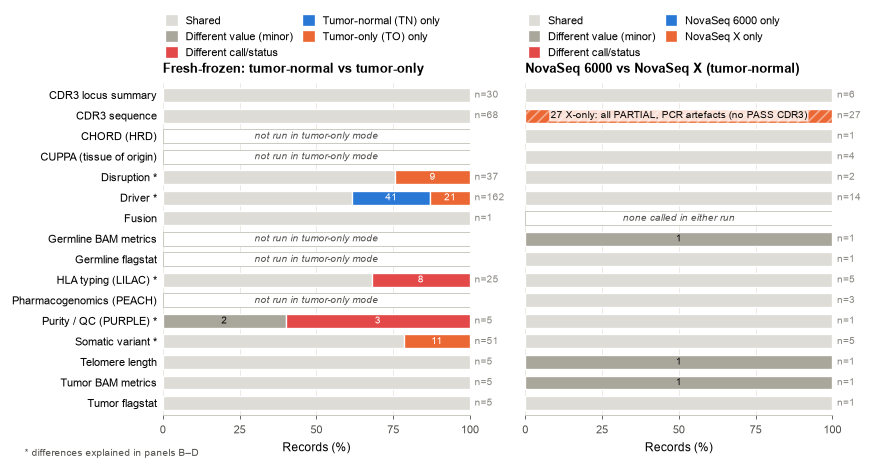

In [7]:
CATEGORY_NAMES = {
    "CDR3_LOCUS_SUMMARY": "CDR3 locus summary", "CDR3_SEQUENCE": "CDR3 sequence",
    "CHORD": "CHORD (HRD)", "CUPPA": "CUPPA (tissue of origin)", "DISRUPTION": "Disruption",
    "DRIVER": "Driver", "FUSION": "Fusion", "GERMLINE_AMP_DEL": "Germline amp/del",
    "GERMLINE_BAM_METRICS": "Germline BAM metrics", "GERMLINE_FLAGSTAT": "Germline flagstat",
    "GERMLINE_SV": "Germline SV", "GERMLINE_VARIANT": "Germline variant", "LILAC": "HLA typing (LILAC)",
    "PEACH": "Pharmacogenomics (PEACH)", "PURITY": "Purity / QC (PURPLE)",
    "SNP_GENOTYPE": "SNP genotype", "SOMATIC_VARIANT": "Somatic variant",
    "TELOMERE_LENGTH": "Telomere length", "TUMOR_BAM_METRICS": "Tumor BAM metrics",
    "TUMOR_FLAGSTAT": "Tumor flagstat", "VIRUS": "Virus", "V_CHORD": "vCHORD",
}
# Categories whose FF TN vs TO differences are explained in panels B–D.
EXPLAINED_CATEGORIES = {"PURITY", "DRIVER", "SOMATIC_VARIANT", "DISRUPTION", "LILAC"}


def draw_concordance(ax, counts, comparison, categories, show_labels=True, mark_explained=False, notes=None):
    """`notes` maps a category to a text that replaces its count labels; its differences are hatched."""
    notes = notes or {}
    y = np.arange(len(categories))[::-1]
    colors = MISMATCH_COLORS
    labels = mismatch_labels(comparison)
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    for yi, category in zip(y, categories):
        if category not in counts.index:
            if category in PER_CATEGORY[comparison]:  # compared, but the file is empty
                reason = "none called in either run"
            else:
                reason = COMPARISONS[comparison]["missing_reason"]
            ax.barh(yi, 100, height=0.68, facecolor="white", edgecolor=AXIS, linewidth=0.5)
            ax.text(50, yi, reason, ha="center", va="center", color=INK_SECONDARY, fontsize=6, style="italic")
            continue
        row = counts.loc[category]
        total = row.sum()
        left = 0.0
        for status in MISMATCH_ORDER:
            n = row[status]
            if n == 0:
                continue
            width = 100 * n / total
            ax.barh(yi, width, left=left, height=0.68, color=colors[status],
                    edgecolor="white", linewidth=0.8)
            if category in notes and status != "MATCH":
                ax.barh(yi, width, left=left, height=0.68, facecolor="none", hatch="////",
                        edgecolor=(1, 1, 1, 0.45), linewidth=0)
            if status != "MATCH" and category not in notes:  # label only the differences
                t = ax.text(left + width / 2, yi, str(n), ha="center", va="center",
                            fontsize=6, color=text_color_on(colors[status]))
                seg_px = ax.transData.transform((width, 0))[0] - ax.transData.transform((0, 0))[0]
                if t.get_window_extent(renderer).width + 2 > seg_px:
                    t.remove()
            left += width
        ax.text(101.5, yi, f"n={total}", ha="left", va="center", fontsize=6, color=INK_MUTED)
        if category in notes:
            ax.text(50, yi, notes[category], ha="center", va="center", fontsize=5.8, color=INK,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))

    ax.set_yticks(y)
    if show_labels:
        names = [CATEGORY_NAMES.get(c, c) + (" *" if mark_explained and c in EXPLAINED_CATEGORIES else "")
                 for c in categories]
        ax.set_yticklabels(names)
    else:
        ax.tick_params(axis="y", labelleft=False)
    ax.set_ylim(-0.6, len(categories) - 0.4)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlabel("Records (%)")
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(axis="x", colors=INK_SECONDARY)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color=GRID, lw=0.4)
    ax.set_title(COMPARISONS[comparison]["title"], loc="left", fontsize=7.5)
    handles = [Patch(color=colors[s], label=labels[s]) for s in MISMATCH_ORDER]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.06), ncol=2,
              handlelength=0.9, handleheight=0.9, columnspacing=1.0, borderaxespad=0)
    return ax


# A category is drawn when either comparison has records for it, or when its file exists but is empty
# in one comparison (e.g. no fusions called) while the other has records.


ALL_CATEGORIES = sorted(set().union(*(c.index for c in COUNTS.values())),
                        key=lambda c: CATEGORY_NAMES.get(c, c))


def cdr3_note(comparison):
    """Explains CDR3_SEQUENCE when no PASS sequence was called in either run (all records are CIDER PARTIAL)."""
    table = PER_CATEGORY[comparison].get("CDR3_SEQUENCE")
    if table is None or table.empty:
        return {}
    filters = pd.concat([table["OldFilter"], table["NewFilter"]]).dropna()
    if (filters == "PASS").any():
        return {}
    counts = COUNTS[comparison].loc["CDR3_SEQUENCE"]
    info = COMPARISONS[comparison]
    if not (counts["NEW_ONLY"] or counts["OLD_ONLY"]):  # nothing to explain when all sequences are shared
        return {}
    parts = [f"{counts['OLD_ONLY']} {info['old_short']}-only" if counts["OLD_ONLY"] else "",
             f"{counts['NEW_ONLY']} {info['new_short']}-only" if counts["NEW_ONLY"] else ""]
    detail = " + ".join(p for p in parts if p)
    return {"CDR3_SEQUENCE": f"{detail}: all PARTIAL, PCR artefacts (no PASS CDR3)"}


def panel_a(axes):
    draw_concordance(axes[0], COUNTS[FFTN_VS_FFTO], FFTN_VS_FFTO, ALL_CATEGORIES, mark_explained=True,
                     notes=cdr3_note(FFTN_VS_FFTO))
    draw_concordance(axes[1], COUNTS[NOVA_COMP], NOVA_COMP, ALL_CATEGORIES, show_labels=False,
                     notes=cdr3_note(NOVA_COMP))


fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.6), sharey=True, gridspec_kw={"wspace": 0.18})
panel_a(axes)
axes[0].text(-0.45, -0.1, "* differences explained in panels B–D", transform=axes[0].transAxes,
             fontsize=6, color=INK_SECONDARY, va="top")
plt.show()

### 5.2 · Panel B — purity and QC change table

One column per sample; the NovaSeq comparison (HG008, same pipeline mode, different instrument) sits on the right as a
control. Cells show *reference → test*; unchanged values are grey. Only what changes a reported result is highlighted:
a status flip, and the TMB / TML / MS indels value that crosses its threshold to cause it. A TMB that changes but stays
above 10 (e.g. 14.3 → 19.6) is still TMB HIGH and is not highlighted.

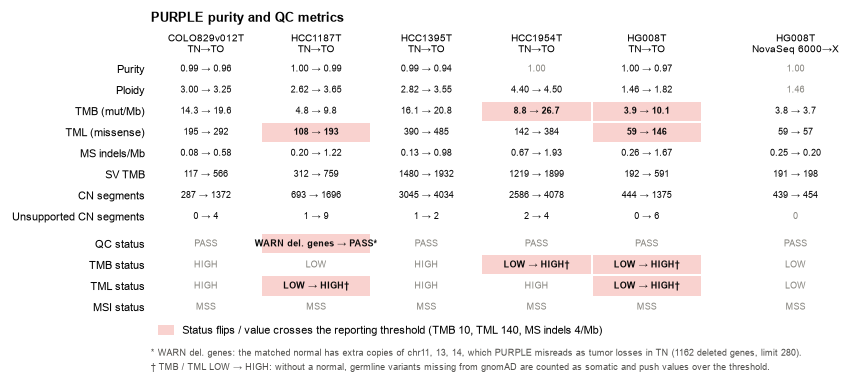

In [8]:
NUMERIC_METRICS = {
    "Purity": ("Purity", "{:.2f}"),
    "Ploidy": ("Ploidy", "{:.2f}"),
    "TmbPerMb": ("TMB (mut/Mb)", "{:.1f}"),
    "Tml": ("TML (missense)", "{:.0f}"),
    "MsIndelsPerMb": ("MS indels/Mb", "{:.2f}"),
    "SvTmb": ("SV TMB", "{:.0f}"),
    "CopyNumberSegments": ("CN segments", "{:.0f}"),
    "UnsupportedCopyNumberSegments": ("Unsupported CN segments", "{:.0f}"),
}
STATUS_METRICS = {
    "QcStatus": "QC status",
    "TmbStatus": "TMB status",
    "TmlStatus": "TML status",
    "MsStatus": "MSI status",
}
STATUS_ABBREVIATIONS = {"WARN_DELETED_GENES": "WARN del. genes"}


def purity_table():
    """One row per (comparison, sample) with Old*/New* purity columns."""
    rows = []
    for comparison in COMPARISONS:
        table = PER_CATEGORY[comparison]["PURITY"].copy()
        table.insert(0, "Comparison", comparison)
        rows.append(table)
    table = pd.concat(rows, ignore_index=True)
    table["Column"] = np.where(table["Comparison"] == NOVA_COMP, table["SampleId"] + "\nNovaSeq 6000→X",
                               table["SampleId"] + "\nTN→TO")
    order = sorted(table.index[table["Comparison"] == FFTN_VS_FFTO], key=lambda i: table.at[i, "SampleId"])
    order += list(table.index[table["Comparison"] == NOVA_COMP])
    return table.loc[order].reset_index(drop=True)


PURITY = purity_table()


def crosses_threshold(metric, old, new):
    threshold = THRESHOLDS.get(metric)
    return threshold is not None and (float(old) < threshold) != (float(new) < threshold)


# Footnote markers on flipped status cells; the explanations are printed under the table.
STATUS_FOOTNOTES = {
    "QcStatus": ("*", "WARN del. genes: the matched normal has extra copies of chr11, 13, 14, which PURPLE misreads "
                      "as tumor losses in TN (1162 deleted genes, limit 280)."),
    "TmbStatus": ("†", "TMB / TML LOW → HIGH: without a normal, germline variants missing from gnomAD are counted as "
                       "somatic and push values over the threshold."),
}
STATUS_FOOTNOTES["TmlStatus"] = STATUS_FOOTNOTES["TmbStatus"]


def panel_b(ax, legend_ax=None):
    n_columns = len(PURITY)
    gap = 0.35  # visual gap before the NovaSeq control column
    xs = [i + (gap if row["Comparison"] == NOVA_COMP else 0) for i, row in PURITY.iterrows()]
    rows = list(NUMERIC_METRICS) + list(STATUS_METRICS)

    for ri, metric in enumerate(rows):
        y = len(rows) - 1 - ri + (0.3 if metric in NUMERIC_METRICS else 0)
        for x, (_, row) in zip(xs, PURITY.iterrows()):
            old, new = row[f"Old{metric}"], row[f"New{metric}"]
            if metric in NUMERIC_METRICS:
                fmt = NUMERIC_METRICS[metric][1]
                changed = fmt.format(float(old)) != fmt.format(float(new))
                highlight = crosses_threshold(metric, old, new)
                text = f"{fmt.format(float(old))} → {fmt.format(float(new))}" if changed else fmt.format(float(old))
            else:
                changed = highlight = old != new
                o, n = (STATUS_ABBREVIATIONS.get(v, v) for v in (old, new))
                text = f"{o} → {n}" if changed else o
                if changed and metric in STATUS_FOOTNOTES:
                    text += STATUS_FOOTNOTES[metric][0]
            fill = STATUS_FLIP_COLOR if highlight else "white"
            ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=fill, edgecolor="white", lw=1.2))
            ax.text(x, y, text, ha="center", va="center", fontsize=5.6,
                    color=INK if changed else INK_MUTED, fontweight="bold" if highlight else "normal")

    yticks = [len(rows) - 1 - ri + (0.3 if m in NUMERIC_METRICS else 0) for ri, m in enumerate(rows)]
    ax.set_yticks(yticks)
    ax.set_yticklabels([NUMERIC_METRICS[m][0] if m in NUMERIC_METRICS else STATUS_METRICS[m] for m in rows])
    ax.set_xticks(xs)
    ax.set_xticklabels(PURITY["Column"], fontsize=6)
    ax.xaxis.tick_top()
    ax.tick_params(axis="x", length=0, pad=2)
    ax.set_xlim(-0.5, xs[-1] + 0.5)
    ax.set_ylim(-0.5, len(rows) - 0.5 + 0.3)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title("PURPLE purity and QC metrics", loc="left", pad=22)

    ax.legend(handles=[Patch(facecolor=STATUS_FLIP_COLOR, label="Status flips / value crosses the reporting "
                             f"threshold (TMB {THRESHOLDS['TmbPerMb']}, TML {THRESHOLDS['Tml']}, "
                             f"MS indels {THRESHOLDS['MsIndelsPerMb']}/Mb)")],
              loc="upper left", bbox_to_anchor=(0, 0.0), handlelength=1.4, handleheight=1.0, borderaxespad=0.3)
    notes = dict(STATUS_FOOTNOTES.values())
    for i, (marker, note) in enumerate(notes.items()):
        ax.text(0.0, -0.12 - 0.055 * i, f"{marker} {note}", transform=ax.transAxes, ha="left", va="top",
                fontsize=5.6, color=INK_SECONDARY)


fig = plt.figure(figsize=(7.2, 3.0))
ax = fig.add_axes([0.17, 0.12, 0.81, 0.72])
panel_b(ax)
plt.show()

### 5.3 · Panel C — metrics with a reporting threshold

TMB, TML and MS indels/Mb drive the TMB / TML / MSI status (FF TN vs TO; the NovaSeq values are in panel B). The
dashed line is the PURPLE threshold. A change only matters for reporting when the arrow crosses it.

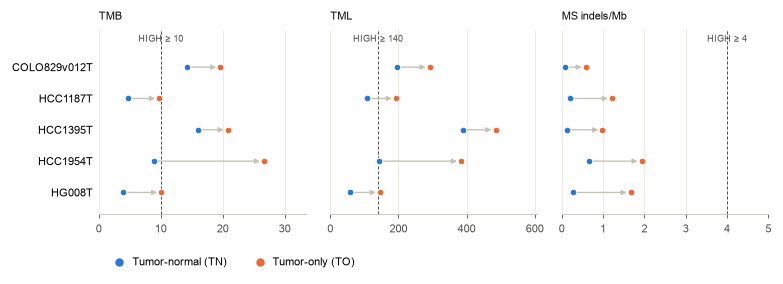

In [9]:
THRESHOLD_METRICS = {
    "TmbPerMb": "TMB",
    "Tml": "TML",
    "MsIndelsPerMb": "MS indels/Mb",
}


def panel_c(axes):
    ff = PURITY[PURITY["Comparison"] == FFTN_VS_FFTO]
    labels = list(ff["SampleId"])
    y = np.arange(len(ff))[::-1].astype(float)
    for ax, (metric, title) in zip(axes, THRESHOLD_METRICS.items()):
        old = ff[f"Old{metric}"].astype(float).to_numpy()
        new = ff[f"New{metric}"].astype(float).to_numpy()
        threshold = THRESHOLDS[metric]
        for yi, o, n in zip(y, old, new):
            ax.annotate("", xy=(n, yi), xytext=(o, yi),
                        arrowprops=dict(arrowstyle="-|>", color=AXIS, lw=0.8, mutation_scale=6,
                                        shrinkA=2.5, shrinkB=2.5))
        ax.scatter(old, y, s=16, color=OLD_COLOR, zorder=3, edgecolor="white", linewidth=0.6)
        ax.scatter(new, y, s=16, color=NEW_COLOR, zorder=3, edgecolor="white", linewidth=0.6)
        ax.axvline(threshold, color=INK_SECONDARY, lw=0.6, ls=(0, (3, 2)), zorder=1)
        ax.text(threshold, y.max() + 0.75, f"HIGH ≥ {threshold}", fontsize=5.5, color=INK_SECONDARY,
                ha="center", va="bottom")
        upper = max(new.max(), old.max(), threshold) * 1.25
        ax.set_xlim(0, upper)
        ax.set_ylim(y.min() - 0.7, y.max() + 1.2)
        ax.set_yticks(y)
        ax.set_yticklabels(labels if ax is axes[0] else [])
        ax.set_title(title, loc="left", fontsize=6.5, fontweight="normal", color=INK)
        ax.spines["left"].set_visible(False)
        ax.spines["bottom"].set_color(AXIS)
        ax.tick_params(axis="x", colors=INK_SECONDARY)
        ax.grid(axis="x", color=GRID, lw=0.4)
        ax.set_axisbelow(True)
    handles = [Line2D([], [], marker="o", ms=4, ls="", color=OLD_COLOR, label="Tumor-normal (TN)"),
               Line2D([], [], marker="o", ms=4, ls="", color=NEW_COLOR, label="Tumor-only (TO)")]
    axes[0].legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.18), ncol=2, handletextpad=0.2)


fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.0), gridspec_kw={"wspace": 0.12})
panel_c(axes)
plt.show()

### 5.4 · Panel D — why FF tumour/normal and tumour-only calls differ

Every record that is TN-only, TO-only or has a different HLA typing, coloured by the root cause from the manual
annotation.

> **This panel is built on manual curation, not on COMPAR output.** Every root cause comes from a
> person reading the discordant records of *this* dataset (the five FF cell lines, TN vs TO) and
> writing a `Conclusion` for each one, stored in `MANUAL_ANNOTATIONS` (section 4.1).
> `root_cause()` then maps those free-text conclusions onto the categories shown by matching
> phrases that occur in our notes.
>
> **If you run COMPAR on your own data**, none of your records are in that list and the panel will
> show them all as *Not annotated*. To get a similar figure you have to redo the analysis:
>
> 1. Review each TN-only / TO-only / different record (IGV, the run's VCFs and PURPLE output).
> 2. Replace the entries in `MANUAL_ANNOTATIONS` with your own, in the same
>    `(Category, SampleId, Key, NewGene, Conclusion)` form.
> 3. Adapt `ROOT_CAUSES` and `root_cause()` (section 4.1) to your conclusions, and `ROOT_CAUSE_ROWS`
>    below to the categories that differ in your data.

Category/status combinations without a predefined row in `ROOT_CAUSE_ROWS` are added automatically,
so the panel still draws on another dataset.

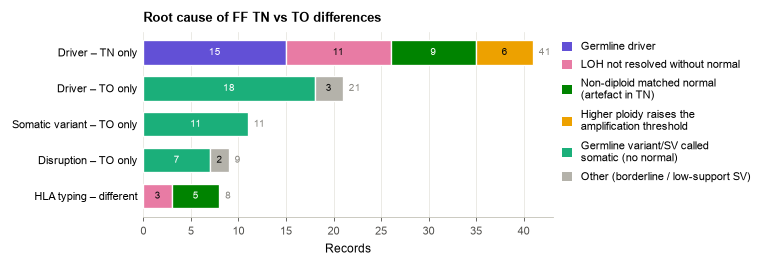

In [10]:
ROOT_CAUSE_ROWS = [
    ("DRIVER", "OLD_ONLY", "Driver – TN only"),
    ("DRIVER", "NEW_ONLY", "Driver – TO only"),
    ("SOMATIC_VARIANT", "NEW_ONLY", "Somatic variant – TO only"),
    ("DISRUPTION", "NEW_ONLY", "Disruption – TO only"),
    ("LILAC", "VALUE_MAJOR", "HLA typing – different"),
]


def panel_d(ax):
    table = pd.crosstab([FF_DISCORDANT["Category"], FF_DISCORDANT["Status"]], FF_DISCORDANT["RootCause"])
    table = table.reindex(columns=list(ROOT_CAUSES), fill_value=0)
    present = [(c, s, label) for c, s, label in ROOT_CAUSE_ROWS if (c, s) in table.index]
    known = {(c, s) for c, s, _ in present}
    labels = mismatch_labels(FFTN_VS_FFTO)
    present += [(c, s, f"{CATEGORY_NAMES.get(c, c)} – {labels[s]}") for c, s in table.index if (c, s) not in known]

    y = np.arange(len(present))[::-1]
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for yi, (category, status, _) in zip(y, present):
        left = 0
        for cause, (_, color) in ROOT_CAUSES.items():
            n = table.loc[(category, status), cause]
            if n == 0:
                continue
            ax.barh(yi, n, left=left, height=0.68, color=color, edgecolor="white" if cause != "unannotated" else AXIS,
                    linewidth=0.8)
            t = ax.text(left + n / 2, yi, str(n), ha="center", va="center", fontsize=6, color=text_color_on(color))
            seg_px = ax.transData.transform((n, 0))[0] - ax.transData.transform((0, 0))[0]
            if t.get_window_extent(renderer).width + 2 > seg_px:
                t.remove()
            left += n
        ax.text(left + 0.6, yi, str(left), va="center", fontsize=6, color=INK_MUTED)

    ax.set_yticks(y)
    ax.set_yticklabels([label for _, _, label in present])
    ax.set_xlabel("Records")
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(axis="x", colors=INK_SECONDARY)
    ax.grid(axis="x", color=GRID, lw=0.4)
    ax.set_axisbelow(True)
    ax.set_title("Root cause of FF TN vs TO differences", loc="left")
    used = [c for c in ROOT_CAUSES if table[c].sum() > 0]
    handles = [Patch(facecolor=ROOT_CAUSES[c][1], edgecolor=AXIS if c == "unannotated" else "none",
                     label=ROOT_CAUSES[c][0]) for c in used]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1.0), handlelength=0.9,
              handleheight=0.9, labelspacing=0.7)


fig, ax = plt.subplots(figsize=(4.4, 2.0))
panel_d(ax)
plt.show()

## 6 · Composite figure

Panels A–D on one canvas. Panel letters are deliberately absent; they are added when the figure is
assembled for the manuscript.

Wrote: figures/ext_compar_concordance.pdf figures/ext_compar_concordance.svg figures/ext_compar_concordance.png


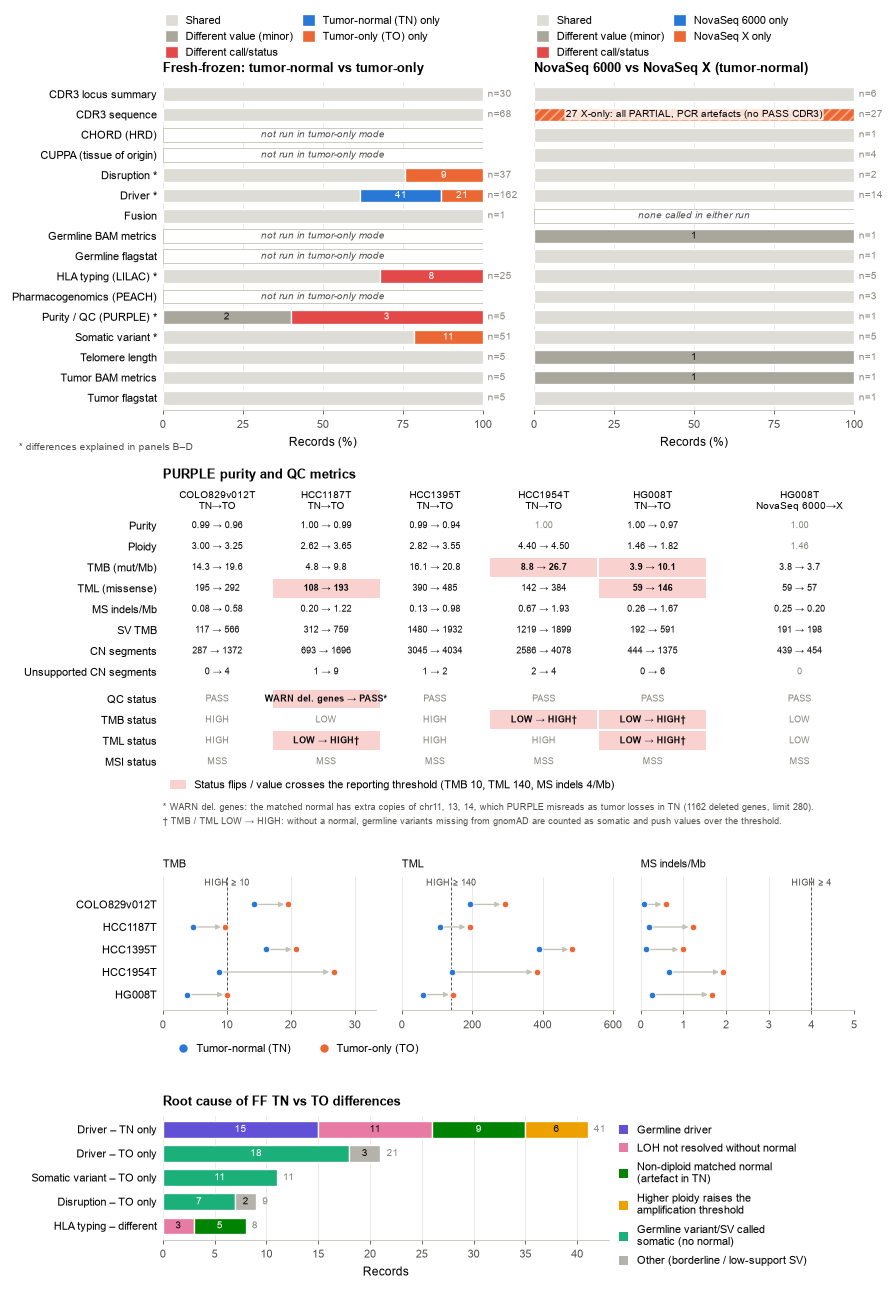

In [11]:
fig = plt.figure(figsize=(7.2, 10.6))
grid = fig.add_gridspec(4, 1, height_ratios=[3.7, 2.9, 1.5, 1.4], hspace=0.5,
                        left=0.17, right=0.97, top=0.95, bottom=0.04)

row_a = grid[0].subgridspec(1, 2, wspace=0.16)
ax_a1 = fig.add_subplot(row_a[0])
ax_a2 = fig.add_subplot(row_a[1], sharey=ax_a1)
panel_a([ax_a1, ax_a2])
ax_a1.text(-0.45, -0.1, "* differences explained in panels B–D", transform=ax_a1.transAxes,
           fontsize=6, color=INK_SECONDARY, va="top")

ax_b = fig.add_subplot(grid[1])
panel_b(ax_b)

row_c = grid[2].subgridspec(1, 3, wspace=0.12)
axes_c = [fig.add_subplot(row_c[i]) for i in range(3)]
panel_c(axes_c)

row_d = grid[3].subgridspec(1, 2, width_ratios=[1.0, 0.55], wspace=0.0)
ax_d = fig.add_subplot(row_d[0])
panel_d(ax_d)

stem = EXPORT_DIR / FIGURE_STEM
for ext in ("pdf", "svg", "png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
plt.show()